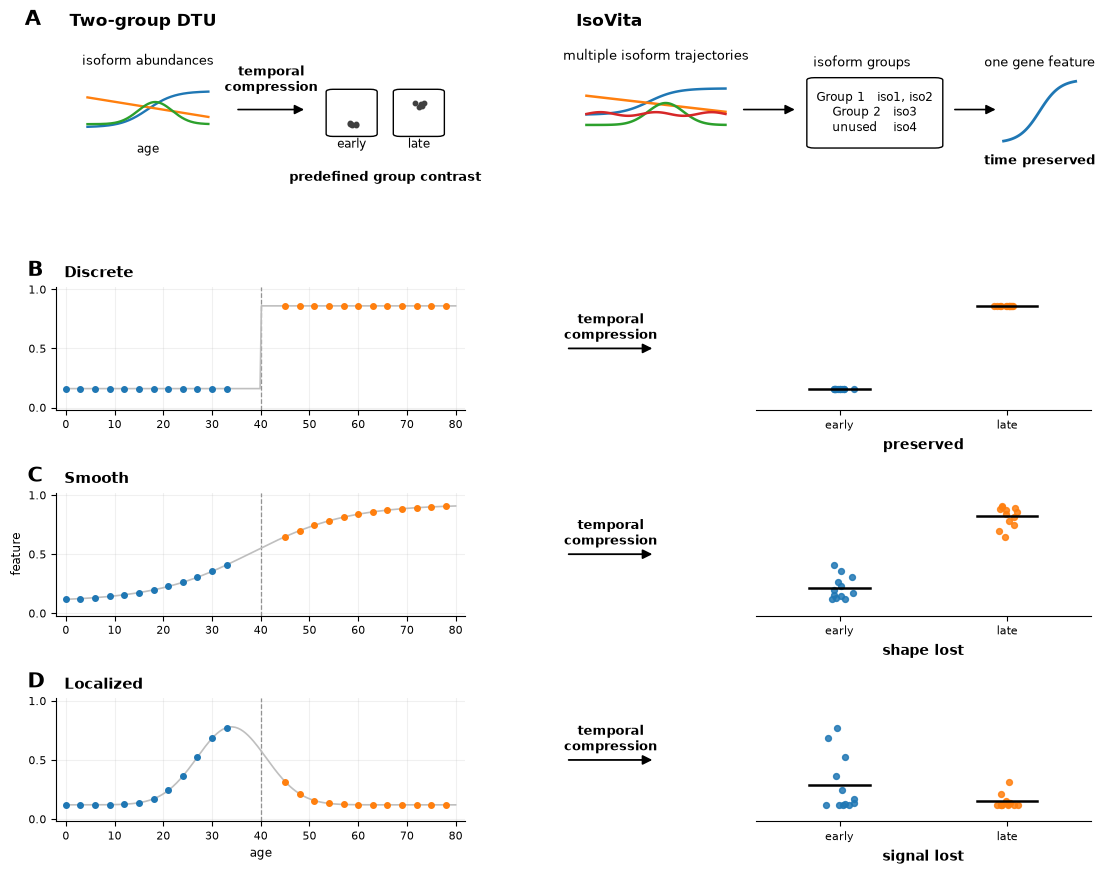

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


# ============================================================
# helpers
# ============================================================

def clean_axis(ax, show_x=True, show_y=True):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if not show_y:
        ax.spines["left"].set_visible(False)
        ax.set_yticks([])
    if not show_x:
        ax.spines["bottom"].set_visible(False)
        ax.set_xticks([])
    ax.tick_params(labelsize=8)


def panel_letter(ax, letter):
    ax.text(
        -0.07, 1.05, letter,
        transform=ax.transAxes,
        fontsize=15, fontweight="bold",
        va="bottom", ha="left"
    )


def arrow_axes(ax, start, end, text=None, text_offset=(0, 0.08), lw=1.2):
    arr = FancyArrowPatch(
        start, end,
        transform=ax.transAxes,
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=lw,
        color="black",
        clip_on=False,
    )
    ax.add_patch(arr)
    if text is not None:
        xm = (start[0] + end[0]) / 2 + text_offset[0]
        ym = (start[1] + end[1]) / 2 + text_offset[1]
        ax.text(
            xm, ym, text,
            transform=ax.transAxes,
            ha="center", va="center",
            fontsize=9, fontweight="bold"
        )


def rounded_box(ax, xy, width, height, text, fontsize=9):
    x, y = xy
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.012,rounding_size=0.015",
        facecolor="white", edgecolor="black", linewidth=1.0,
        transform=ax.transAxes, clip_on=False
    )
    ax.add_patch(patch)
    ax.text(
        x + width / 2, y + height / 2, text,
        transform=ax.transAxes,
        ha="center", va="center", fontsize=fontsize
    )
    return patch


# ============================================================
# conceptual trajectories on a 0–1 scale
# ============================================================

def conceptual_trajectory(kind, age):
    if kind == "discrete":
        return np.where(age < 40, 0.16, 0.86)
    if kind == "smooth":
        return 0.10 + 0.82 / (1 + np.exp(-(age - 38) / 10))
    if kind == "localized":
        return 0.12 + 0.66 * np.exp(-((age - 34) / 10) ** 2)
    raise ValueError(kind)


# ============================================================
# Panel A
# ============================================================

def panel_A_conventional(ax):
    ax.set_axis_off()
    panel_letter(ax, "A")

    ax.text(
        0.03, 1.05, "Two-group DTU",
        transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="bottom"
    )

    t = np.linspace(0, 1, 160)

    x0, x1 = 0.07, 0.34
    y0, y1 = 0.42, 0.73

    curves = [
        # isoform 1: increasing
        0.14 + 0.70 / (1 + np.exp(-(t - 0.50) * 9)),

        # isoform 2: decreasing
        0.72 - 0.38 * t,

        # isoform 3: localized pattern
        0.20 + 0.43 * np.exp(-((t - 0.56) / 0.20) ** 2),
    ]

    cols = [
        "tab:blue",
        "tab:orange",
        "tab:green",
    ]

    for curve, col in zip(curves, cols):
        xx = x0 + (x1 - x0) * t
        yy = y0 + (y1 - y0) * curve

        ax.plot(
            xx, yy,
            lw=1.7,
            color=col,
            transform=ax.transAxes,
            clip_on=False
        )

    ax.text(
        (x0 + x1) / 2,
        0.84,
        "isoform abundances",
        transform=ax.transAxes,
        ha="center",
        fontsize=9
    )

    ax.text(
        (x0 + x1) / 2,
        0.31,
        "age",
        transform=ax.transAxes,
        ha="center",
        fontsize=8.5
    )

    # Temporal information is reduced to a predefined
    # early-versus-late contrast.
    arrow_axes(
        ax,
        (0.40, 0.57),
        (0.56, 0.57),
        "temporal\ncompression",
        (0, 0.18)
    )

    grouped = {
        "early": np.array([
            0.15, 0.16, 0.17,
            0.18, 0.19, 0.20
        ]),
        "late": np.array([
            0.76, 0.80, 0.82,
            0.85, 0.87, 0.89
        ]),
    }

    for x, label, seed in [
        (0.66, "early", 11),
        (0.81, "late", 12),
    ]:
        rounded_box(
            ax,
            (x - 0.045, 0.42),
            0.09,
            0.26,
            "",
            fontsize=8
        )

        rng = np.random.default_rng(seed)
        vals = grouped[label]

        vals_scaled = 0.45 + 0.18 * vals

        for v in vals_scaled:
            ax.plot(
                x + rng.normal(scale=0.007),
                v,
                "o",
                ms=3.2,
                transform=ax.transAxes,
                color="0.25",
                clip_on=False
            )

        ax.text(
            x,
            0.34,
            label,
            transform=ax.transAxes,
            ha="center",
            fontsize=8.5
        )

    ax.text(
        0.735,
        0.14,
        "predefined group contrast",
        transform=ax.transAxes,
        ha="center",
        fontsize=9,
        fontweight="bold"
    )


def panel_A_isovita(ax):
    ax.set_axis_off()

    ax.text(
        0.00, 1.05, "IsoVita",
        transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="bottom"
    )

    t = np.linspace(0, 1, 120)

    x0, x1 = 0.02, 0.29
    y0, y1 = 0.42, 0.75

    curves = [
        0.60 + 0.18 * np.tanh((t - 0.45) * 5),
        0.68 - 0.22 * t,
        0.28 + 0.30 * np.exp(-((t - 0.57) / 0.18) ** 2),
        0.43 + 0.025 * np.sin(5 * np.pi * t),
    ]

    cols = [
        "tab:blue",
        "tab:orange",
        "tab:green",
        "tab:red",
    ]

    for curve, col in zip(curves, cols):
        xx = x0 + (x1 - x0) * t
        yy = y0 + (y1 - y0) * (curve - 0.15) / 0.75

        ax.plot(
            xx,
            yy,
            lw=1.8,
            color=col,
            transform=ax.transAxes,
            clip_on=False
        )

    ax.text(
        (x0 + x1) / 2,
        0.87,
        "multiple isoform trajectories",
        transform=ax.transAxes,
        ha="center",
        fontsize=9
    )

    arrow_axes(
        ax,
        (0.32, 0.57),
        (0.43, 0.57)
    )

    rounded_box(
        ax,
        (0.46, 0.35),
        0.24,
        0.40,
        "Group 1   iso1, iso2\n"
        "Group 2   iso3\n"
        "unused    iso4",
        fontsize=8.8
    )

    ax.text(
        0.555,
        0.83,
        "isoform groups",
        transform=ax.transAxes,
        ha="center",
        fontsize=9
    )

    arrow_axes(
        ax,
        (0.73, 0.57),
        (0.82, 0.57)
    )

    tt = np.linspace(0, 1, 120)

    feature = (
        0.12
        + 0.76 / (1 + np.exp(-(tt - 0.5) * 7))
    )

    xx = 0.83 + 0.14 * tt
    yy = (
        0.38
        + 0.36
        * (feature - feature.min())
        / (feature.max() - feature.min())
    )

    ax.plot(
        xx,
        yy,
        lw=2.0,
        transform=ax.transAxes,
        clip_on=False
    )

    ax.text(
        0.90,
        0.83,
        "one gene feature",
        transform=ax.transAxes,
        ha="center",
        fontsize=9
    )

    ax.text(
        0.90,
        0.24,
        "time preserved",
        transform=ax.transAxes,
        ha="center",
        fontsize=9,
        fontweight="bold"
    )


# ============================================================
# Panels B-D
# ============================================================

def sample_points(kind):
    early_age = np.arange(0, 36, 3)
    late_age = np.arange(45, 81, 3)

    age = np.concatenate([
        early_age,
        late_age
    ])

    y = conceptual_trajectory(
        kind,
        age
    )

    return age, y


def add_split_line(ax):
    ax.axvline(
        40,
        linestyle="--",
        lw=0.9,
        color="0.55",
        zorder=0
    )


def row_left(ax, letter, name, kind):
    panel_letter(ax, letter)

    ax.text(
        0.02,
        1.05,
        name,
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="bottom"
    )

    age, y = sample_points(kind)

    fine_age = np.linspace(
        0,
        80,
        300
    )

    fine_y = conceptual_trajectory(
        kind,
        fine_age
    )

    ax.plot(
        fine_age,
        fine_y,
        color="0.75",
        lw=1.2,
        zorder=1
    )

    early_mask = age < 40
    late_mask = age > 40

    ax.scatter(
        age[early_mask],
        y[early_mask],
        s=16,
        color="tab:blue",
        zorder=2,
        clip_on=False
    )

    ax.scatter(
        age[late_mask],
        y[late_mask],
        s=16,
        color="tab:orange",
        zorder=2,
        clip_on=False
    )

    add_split_line(ax)

    ax.set_xlim(
        -2,
        82
    )

    ax.set_ylim(
        -0.02,
        1.02
    )

    ax.set_yticks([
        0,
        0.5,
        1.0
    ])

    ax.grid(
        alpha=0.18
    )

    clean_axis(ax)

    if letter == "D":
        ax.set_xlabel(
            "age",
            fontsize=8.5
        )
    else:
        ax.set_xlabel("")

    if letter == "C":
        ax.set_ylabel(
            "feature",
            fontsize=8.5
        )
    else:
        ax.set_ylabel("")


def row_middle(ax):
    ax.set_axis_off()

    arrow_axes(
        ax,
        (0.15, 0.50),
        (0.85, 0.50),
        "temporal\ncompression",
        (0, 0.17),
        lw=1.3
    )


def row_right(ax, kind, outcome):
    age, y = sample_points(kind)

    early = y[age < 40]
    late = y[age > 40]

    rng1 = np.random.default_rng(
        {
            "discrete": 111,
            "smooth": 112,
            "localized": 113,
        }[kind]
    )

    rng2 = np.random.default_rng(
        {
            "discrete": 211,
            "smooth": 212,
            "localized": 213,
        }[kind]
    )

    xj1 = (
        1
        + rng1.normal(
            0,
            0.035,
            len(early)
        )
    )

    xj2 = (
        2
        + rng2.normal(
            0,
            0.035,
            len(late)
        )
    )

    ax.scatter(
        xj1,
        early,
        s=18,
        alpha=0.85,
        color="tab:blue",
        zorder=2,
        clip_on=False
    )

    ax.scatter(
        xj2,
        late,
        s=18,
        alpha=0.85,
        color="tab:orange",
        zorder=2,
        clip_on=False
    )

    for xpos, vals in [
        (1, early),
        (2, late)
    ]:
        m = np.mean(vals)

        ax.plot(
            [
                xpos - 0.18,
                xpos + 0.18
            ],
            [
                m,
                m
            ],
            color="black",
            lw=1.8,
            zorder=3
        )

    ax.set_xlim(
        0.5,
        2.5
    )

    ax.set_xticks(
        [1, 2],
        [
            "early",
            "late"
        ]
    )

    ax.set_ylim(
        -0.02,
        1.02
    )

    ax.grid(
        axis="y",
        alpha=0.18
    )

    clean_axis(
        ax,
        show_y=False
    )

    ax.text(
        0.5,
        -0.23,
        outcome,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )


# ============================================================
# assemble figure
# ============================================================

def make_figure(path=None):
    fig = plt.figure(
        figsize=(11.5, 8.9)
    )

    outer = gridspec.GridSpec(
        4,
        1,
        figure=fig,
        height_ratios=[
            1.35,
            1.0,
            1.0,
            1.0
        ],
        hspace=0.62,
    )

    top = outer[0].subgridspec(
        1,
        2,
        width_ratios=[
            1.0,
            1.15
        ],
        wspace=0.15
    )

    axA1 = fig.add_subplot(
        top[0, 0]
    )

    axA2 = fig.add_subplot(
        top[0, 1]
    )

    panel_A_conventional(
        axA1
    )

    panel_A_isovita(
        axA2
    )

    rows = [
        (
            "B",
            "Discrete",
            "discrete",
            "preserved"
        ),
        (
            "C",
            "Smooth",
            "smooth",
            "shape lost"
        ),
        (
            "D",
            "Localized",
            "localized",
            "signal lost"
        ),
    ]

    for i, (
        letter,
        name,
        kind,
        outcome
    ) in enumerate(
        rows,
        start=1
    ):
        row = outer[i].subgridspec(
            1,
            3,
            width_ratios=[
                1.22,
                0.38,
                1.0
            ],
            wspace=0.28
        )

        axL = fig.add_subplot(
            row[0, 0]
        )

        axM = fig.add_subplot(
            row[0, 1]
        )

        axR = fig.add_subplot(
            row[0, 2]
        )

        row_left(
            axL,
            letter,
            name,
            kind
        )

        row_middle(
            axM
        )

        row_right(
            axR,
            kind,
            outcome
        )

    fig.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.96,
        bottom=0.08
    )

    if path is not None:
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

    return fig


if __name__ == "__main__":
    fig = make_figure()
    plt.show()